# Exercise 18 – Describing clusters with numbers: distance moments

**Week 4 · Descriptors and unsupervised learning**

The dataset contains 38 relaxed Lennard-Jones clusters of 10 atoms. To
compare or classify structures, each cluster is mapped to a short feature
vector – a *descriptor*. A good descriptor is invariant to translation,
rotation and the numbering of the atoms.

The simplest choice: the mean $\mu$ and standard deviation $\sigma$ of all
interatomic distances. Compact clusters have small $\mu$, elongated ones large $\mu$.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from comphy import DATA_DIR
from comphy.atoms import LennardJones
from comphy.clusters import draw_gallery, plot_cluster
from comphy.descriptors import DistanceMoments

raw = np.loadtxt(DATA_DIR / "lj10clusters.txt")
positions = raw.reshape(len(raw), -1, 2)
calc = LennardJones()
descriptor = DistanceMoments()
print(f"{len(positions)} clusters of {positions.shape[1]} atoms")

38 clusters of 10 atoms


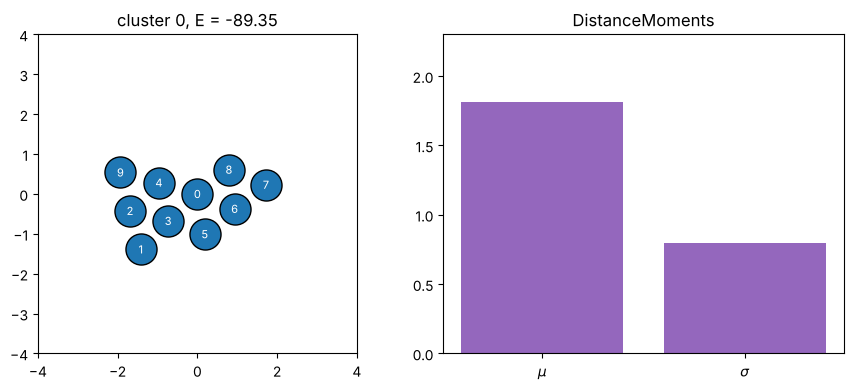

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
plot_cluster(axes[0], positions[0], size=500)
axes[0].set(xlim=(-4, 4), ylim=(-4, 4), title=f"cluster 0, E = {calc.energy(positions[0]):.2f}")
descriptor.draw(axes[1], positions[0])
fig.tight_layout()
plt.show()

## Descriptor space
Every cluster becomes a point $(\mu, \sigma)$. Grouping by hand into bins of
$\mu$ already separates compact from elongated structures.

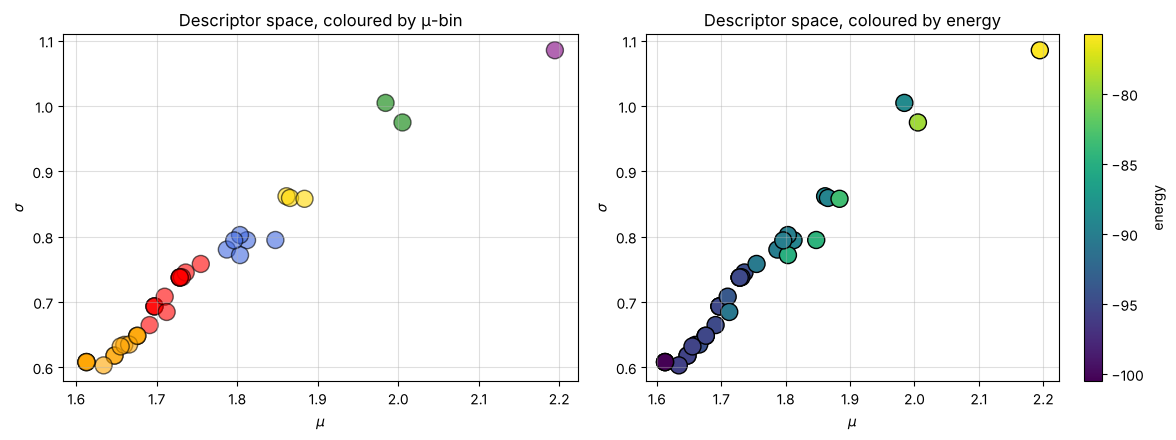

In [3]:
X = np.array([descriptor(p) for p in positions])
energies = np.array([calc.energy(p) for p in positions])
bins = [0, 1.68, 1.78, 1.85, 1.95, 2.1, np.inf]
bin_colors = ["orange", "red", "royalblue", "gold", "green", "purple"]
group = np.digitize(X[:, 0], bins) - 1
colors = [bin_colors[g] for g in group]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(X[:, 0], X[:, 1], s=150, c=colors, alpha=0.6, edgecolor="black")
axes[0].set(xlabel=r"$\mu$", ylabel=r"$\sigma$", title="Descriptor space, coloured by μ-bin")
sc = axes[1].scatter(X[:, 0], X[:, 1], s=150, c=energies, cmap="viridis", edgecolor="black")
fig.colorbar(sc, ax=axes[1], label="energy")
axes[1].set(xlabel=r"$\mu$", ylabel=r"$\sigma$", title="Descriptor space, coloured by energy")
for ax in axes:
    ax.grid(True, alpha=0.4)
fig.tight_layout()
plt.show()

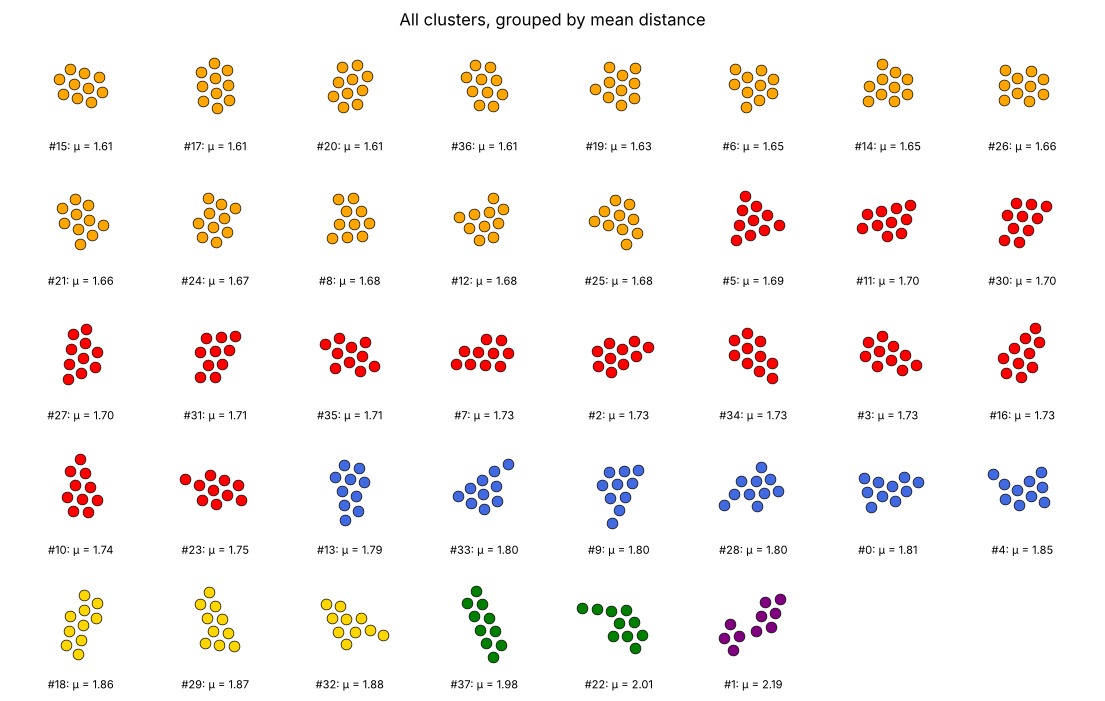

In [4]:
order = np.lexsort((X[:, 0], group))
fig, ax = plt.subplots(figsize=(14, 9))
draw_gallery(ax, positions[order], colors=[colors[i] for i in order], ncols=8,
             labels=[f"#{i}: μ = {X[i, 0]:.2f}" for i in order], size=60)
ax.set_title("All clusters, grouped by mean distance")
plt.show()